In [1]:
import sys
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
sys.path.insert(0, str(Path('src').resolve()))
from student_dropout.data import load_data

# Default: inspect frozen results without fitting or scoring reserved rows.
RESULTS = Path('assets/results')
split = json.loads((RESULTS / 'split.json').read_text())
training = load_data().iloc[split['train']].copy()
print('Training:', len(training), 'Reserved test:', len(split['test']))
print(training.Target.value_counts())

Training: 3539 Reserved test: 885
Target
Graduate    1767
Dropout     1137
Enrolled     635
Name: count, dtype: int64


# Part II: Training and Tuning
Run from the project root. By default this notebook reads the original saved results; it does not fit models. Full reproduction is an explicit separate command documented in README.md and writes outputs/part2. It is expensive and was not repeated during repository preparation.

Q3 predicts recorded Dropout by normal course-end from 18 enrolment fields; Enrolled is not eventual graduation. The frozen three-class-stratified 80/20 split uses seed 481 (3,539 training; 885 reserved). Nested 5 x 3 CV keeps encoding, scaling, splines and tuning inside the corresponding training folds. Final training-only search uses seed 581. Historical full-sample EDA indirectly explored the reserved sample; no held-out candidate comparison has been performed.

B0 is prevalence; P1 ridge logit; P2 penalized spline logit; P3 forest; P4 shallow boosting. P1B is a Brier-objective sensitivity with multiple starts. Outer scores compare training procedures; final refits use all training rows. See part1_candidates.ipynb for assumptions and the original expected ranking.

In [22]:
results = json.loads((RESULTS / 'summary.json').read_text())
display(pd.DataFrame(results).drop(columns=['starts'], errors='ignore'))

,candidate,log_loss,brier,average_precision,precision,recall,f1,prevalence,n_coefficients,intercept,coef_norm,n_trees,mean_depth,mean_leaves
0,B0,0.627829,0.218058,0.320915,0.000000,0.000000,0.000000,0.321277,NaN,NaN,NaN,NaN,NaN,NaN
1,P1,0.541112,0.180907,0.595148,0.631893,0.372911,0.469027,NaN,220.0,-1.143984,4.009674,NaN,NaN,NaN
2,P2,0.539911,0.180476,0.595166,0.628912,0.371152,0.466814,NaN,232.0,-1.428518,3.932167,NaN,NaN,NaN
3,P3,0.550161,0.185276,0.559108,0.618759,0.359719,0.454950,NaN,NaN,NaN,NaN,500.0,8.0,85.38
4,P4,0.539483,0.180464,0.595837,0.652968,0.377309,0.478261,NaN,NaN,NaN,NaN,100.0,2.0,3.97
5,P1B,0.542184,0.181208,0.591609,0.637363,0.357080,0.457723,NaN,220.0,-0.959769,2.878288,NaN,NaN,NaN


## Q2: Three-class adjusted associations
The saved analysis fitted multinomial likelihood with Graduate reference, all 17 programmes, Gender, a four-df age spline and two grade variables. It checks rank, sparse cells, separation and optimizer agreement; reports HC0 sandwich coefficient SEs and delta-method standardized contrast SEs. A 200-resample student bootstrap is sensitivity evidence because rare cells may disappear. These are associations, not causal effects. The former support-offer effect remains unidentifiable; revised Q4 below assesses review allocation instead.

In [23]:
inference_diagnostics = json.loads((RESULTS / 'Q2_diagnostics.json').read_text())
contrasts = pd.read_csv(RESULTS / 'Q2_contrasts.csv')
print(inference_diagnostics)
display(contrasts)

,contrast,dropout_probability_difference,robust_delta_se,normal_ci_low,normal_ci_high,bootstrap_se,ci_low,ci_high
0,Gender: male - female,0.113934,0.017540,0.079557,0.148312,0.017809,0.081931,0.149738
1,Age: 25 - 20 years,0.205401,0.018365,0.169406,0.241396,0.018308,0.173037,0.243513
2,Admission grade: 140 - 130,-0.026216,0.005642,-0.037274,-0.015158,0.005523,-0.037210,-0.015819
3,Previous grade: 140 - 130,-0.002166,0.006571,-0.015045,0.010713,0.006612,-0.015883,0.011346


## Training diagnostics and Q1
The tables and figure below are frozen results from the completed training-only analysis. Q1 uses 2,904 resolved training observations; main.ipynb separately retains the historical full-sample description. Saved metrics are not a new evaluation. Full reproduction performs fold-containment, event-mapping, gradient and deterministic-refit checks using the existing implementation.

,candidate,log_loss,brier,average_precision,precision,recall,f1,calibration_intercept,calibration_slope
0,B0,0.627829,0.218058,0.320915,0.000000,0.000000,0.000000,NaN,NaN
1,P1,0.541112,0.180907,0.595148,0.631893,0.372911,0.469027,-0.055107,0.926621
2,P2,0.539911,0.180476,0.595166,0.628912,0.371152,0.466814,-0.036127,0.953083
3,P3,0.550161,0.185276,0.559108,0.618759,0.359719,0.454950,-0.019075,0.958651
4,P4,0.539483,0.180464,0.595837,0.652968,0.377309,0.478261,0.020882,1.048974
5,P1B,0.542184,0.181208,0.591609,0.637363,0.357080,0.457723,-0.029826,1.013643


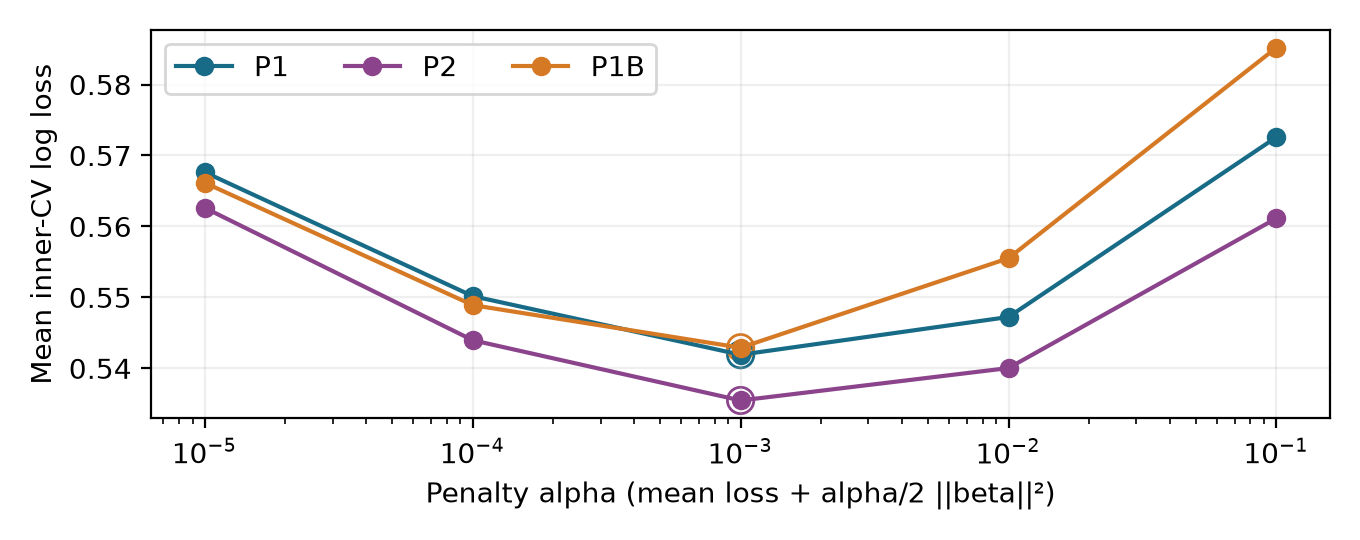

In [24]:
metrics_table = pd.read_csv(RESULTS / 'metrics.csv')
display(metrics_table)
display(Image(filename=str(RESULTS / 'cv_curve.png')))

In [5]:
display(pd.read_csv(RESULTS / 'Q1_training.csv'))
display(pd.read_csv(RESULTS / 'Q1_training_by_course.csv'))

,Unnamed: 0,Age at enrollment,Age at enrollment.1,Age at enrollment.2,Admission grade,Admission grade.1,Admission grade.2,Previous qualification (grade),Previous qualification (grade).1,Previous qualification (grade).2,Gender,Gender.1,Gender.2
0,NaN,size,mean,median,size,mean,median,size,mean,median,size,mean,median
1,Target,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Dropout,1137,26.088830255057168,23.0,1137,124.70290237467019,122.9,1137,130.90404573438875,133.0,1137,0.49780123131046616,0.0
3,Graduate,1767,21.920769666100735,19.0,1767,128.56638370118844,127.3,1767,134.0366723259762,133.1,1767,0.2501414827391058,0.0


,Unnamed: 0,Unnamed: 1,Age at enrollment,Age at enrollment.1,Admission grade,Admission grade.1
0,NaN,NaN,size,mean,size,mean
1,Course,Target,NaN,NaN,NaN,NaN
2,33,Dropout,7,31.571428571428573,7,118.22857142857143
3,33,Graduate,1,26.0,1,118.6
4,171,Dropout,66,21.742424242424242,66,131.4348484848485
5,171,Graduate,77,19.844155844155843,77,140.75974025974025
6,8014,Dropout,57,35.175438596491226,57,119.61929824561403
7,8014,Graduate,102,32.90196078431372,102,124.54117647058824
8,9003,Dropout,66,30.439393939393938,66,126.46969696969697
9,9003,Graduate,71,28.028169014084508,71,138.0394366197183


## Q4: Review allocation (decision, not intervention effect)
Fixed scenarios are 5%, 10% and 20%. Evaluate every pre-existing candidate rule without choosing a winner. Rank only within each outer validation fold; k=floor(q*N). Ties use SHA256(1481:row_id), independent of outcomes. Compare H identified Dropout with exact random expectation k*D/N; pool counts, not probability ranks.

Reuse the saved nested-CV OOF predictions after checking their provenance; no in-sample or test predictions. Exact random-reference uncertainty concerns a hypothetical random list. The 2,000 empirical-pair bootstrap replicates within fixed folds are conditional composition sensitivity only: they do not capture model training/selection uncertainty or remove shared-training dependence. High risk does not mean treatment benefit. The original causal question remains unidentifiable and is replaced explicitly, without claiming instructor approval.

In [26]:
q4_results = pd.read_csv(RESULTS / 'Q4_summary.csv')
display(q4_results.round(3))

,candidate,capacity,n,dropouts,k,identified,precision,recall,random_expected,extra_identified,lift,random_selection_sd,random_reference_low,random_reference_high,conditional_bootstrap_se,conditional_bootstrap_low,conditional_bootstrap_high
0,B0,0.05,3539,1137,175,56,0.320,0.049,56.223,-0.223,0.996,6.027,-12,11,6.129,-12.261,11.887
1,B0,0.10,3539,1137,350,111,0.317,0.098,112.447,-1.447,0.987,8.299,-18,15,8.559,-18.743,14.389
2,B0,0.20,3539,1137,705,223,0.316,0.196,226.500,-3.500,0.985,11.103,-25,18,11.372,-25.309,19.921
3,P1,0.05,3539,1137,175,135,0.771,0.119,56.223,78.777,2.401,6.027,67,90,5.454,69.569,91.101
4,P1,0.10,3539,1137,350,249,0.711,0.219,112.447,136.553,2.214,8.299,120,153,8.148,121.823,153.677
5,P1,0.20,3539,1137,705,443,0.628,0.390,226.500,216.500,1.956,11.103,195,238,11.548,193.705,238.287
6,P2,0.05,3539,1137,175,138,0.789,0.121,56.223,81.777,2.454,6.027,70,93,5.405,71.567,92.470
7,P2,0.10,3539,1137,350,252,0.720,0.222,112.447,139.553,2.241,8.299,123,156,8.187,123.421,155.378
8,P2,0.20,3539,1137,705,444,0.630,0.391,226.500,217.500,1.960,11.103,196,239,11.406,192.309,236.946
9,P3,0.05,3539,1137,175,132,0.754,0.116,56.223,75.777,2.348,6.027,64,87,5.726,63.017,85.251


## Post-review diagnostics: comparison, interpretation and subgroups
These are exploratory checks, not new model selection. P2/P4 lists are compared on the same folds/capacities; paired bootstrap differences reuse the same conditional empirical resamples. Course, Gender and fixed age bins describe the original lists without subgroup quotas or reranking.

For permutation importance and PDP, only ten fixed-parameter outer models (P2/P4 x five folds) were reconstructed, because those fitted fold models were not originally saved. Every reconstructed validation prediction matched the saved OOF score within 1e-10. No search or test prediction was performed; original final models remain unchanged. Feature importance and PDP are model descriptions, not causal effects, and correlated features can produce unrealistic combinations. PR/calibration plots pool OOF scores descriptively; Q4 continues to rank within folds.

,k,both,P2_only,P4_only,both_dropouts,P2_only_dropouts,P4_only_dropouts,difference_P2_minus_P4,capacity,overlap_fraction,conditional_paired_se,conditional_paired_low,conditional_paired_high
0,175,124,51,51,106,32,28,4,0.05,0.709,5.212,-5.025,15.0
1,350,265,85,85,195,57,50,7,0.10,0.757,7.064,-12.000,16.0
2,705,565,140,140,376,68,76,-8,0.20,0.801,8.866,-26.000,9.0


,candidate,capacity,dimension,group,n,dropouts,selected,identified,selection_rate,precision,recall,sparse
109,P2,0.1,Gender,Female,2278,571,99,69,0.043459,0.696970,0.120841,False
110,P2,0.1,Gender,Male,1261,566,251,183,0.199048,0.729084,0.323322,False
247,P4,0.1,Gender,Female,2278,571,85,56,0.037313,0.658824,0.098074,False
248,P4,0.1,Gender,Male,1261,566,265,189,0.210151,0.713208,0.333922,False


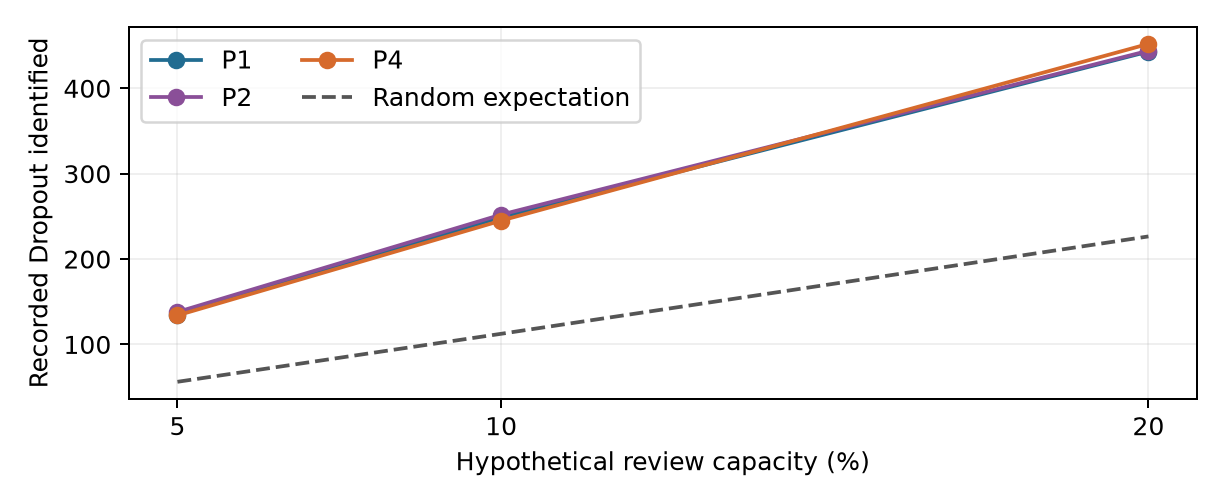

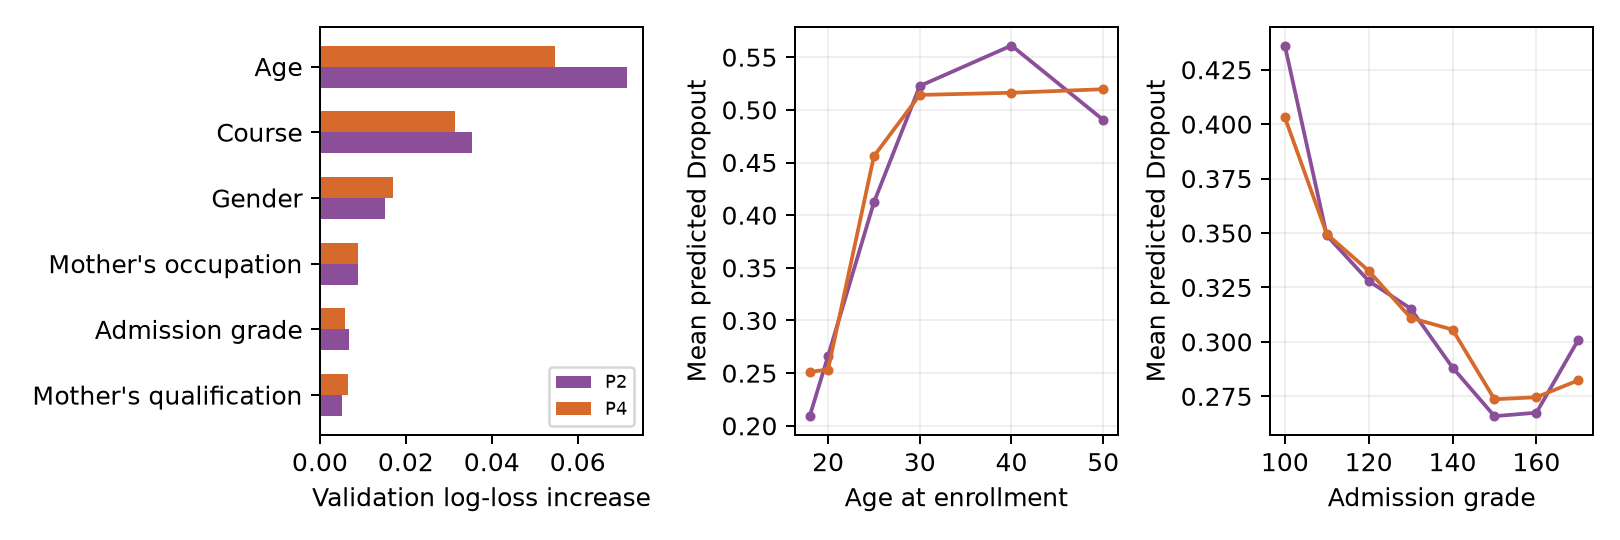

In [30]:
paired_review = pd.read_csv(RESULTS / 'review_paired_summary.csv')
subgroup_review = pd.read_csv(RESULTS / 'review_subgroups.csv')
display(paired_review.round(3))
display(subgroup_review[(subgroup_review.capacity == .1) & (subgroup_review.candidate.isin(['P2','P4'])) & (subgroup_review.dimension == 'Gender')])
display(Image(filename=str(RESULTS / 'review_capacity.png')))
display(Image(filename=str(RESULTS / 'review_interpretation.png')))

## Interpretation of the frozen results

P4 has the lowest nested training-only OOF log loss (0.539483), closely followed by P2 (0.539911). The 0.000428 difference does not establish stable superiority. P4 is the working production choice under the declared OOF-loss rule, not a held-out winner. The finite search is not a proof of global hyperparameter optimality. P2 uses a ridge penalty on standardized spline coefficients, not a second-derivative roughness penalty. P1B uses multiple optimizer starts and remains sensitive to local optima.

Q2 retains Graduate, Dropout and Enrolled. The multinomial Newton fit converged in 7 iterations; an independent BFGS fit agreed numerically but reported precision loss. Two course-outcome cells have fewer than five observations; 89 of 200 bootstrap resamples have empty cells. Primary uncertainty therefore uses HC0 sandwich and conditional delta-method standard errors; the bootstrap is sensitivity evidence. Population coverage and unknown dependence remain unresolved. The standardized contrasts are adjusted associations, not causal effects.

At 10% review capacity, P2 and P4 identify 252 and 245 recorded Dropout cases versus 112.447 expected under equal-capacity random review. Their paired difference is 7 cases (conditional bootstrap SE 7.06, sensitivity limits -12 to 16), not evidence of a stable winner. Age and Course have the largest held-out permutation importance in the exploratory interpretation. Importance, PDP and subgroup differences do not establish causality or fairness. Q4 uncertainty conditions on fixed predictions and excludes refitting/selection uncertainty. The original causal effect and its standard error remain unestimated; this does not satisfy the assignment's numerical causal-estimate requirement.

In [8]:
print('Frozen training results loaded. No fitting or held-out scoring was performed.')

Frozen training results loaded. No fitting or held-out scoring was performed.
